# Лабораторная работа 11

### Глубокое изучение

Инициализируем Keras
 
В качестве бэкенда используется jax
 
Бэкенд указываем до импорта keras

In [ ]:
import os

os.environ["KERAS_BACKEND"] = "jax"
import keras

print (keras.__version__)

3.9.2


### Классификация

Загружаем набор данных для задачи классификации:

Датасет содержит снимки со спутника 2 видов (desert, water). Загружаем файлы из папки.

Было загружено 2262 изображений.


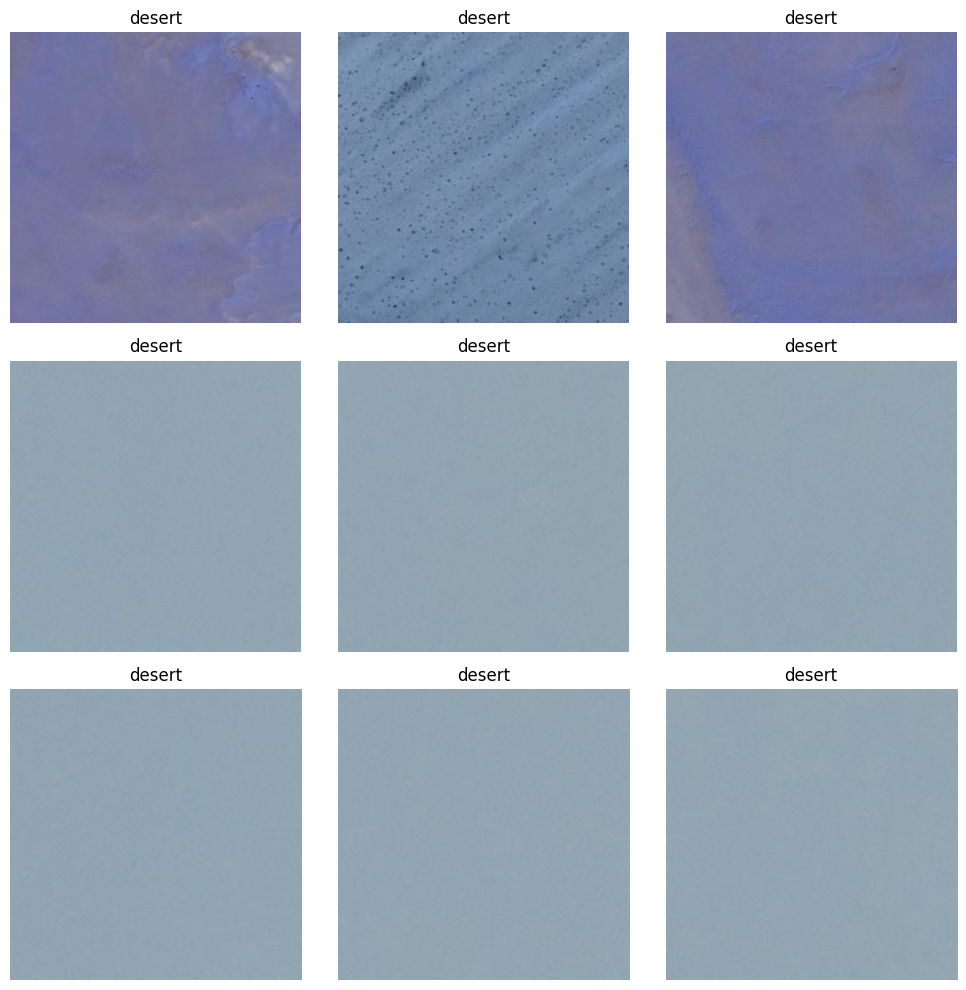

In [27]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def load_images_from_folder(folder):
    images = []
    labels = []
    for label in os.listdir(folder):
        if label in ["desert", "water"]:
            label_folder = os.path.join(folder, label)
            if os.path.isdir(label_folder):
                for filename in os.listdir(label_folder):
                    img_path = os.path.join(label_folder, filename)
                    img = cv2.imread(img_path)
                    if img is not None:
                        img_resized = cv2.resize(img, (512, 512))
                        images.append(img_resized)
                        labels.append(label)
    return images, labels

folder_path = "../data/images/Satellite"
images, labels = load_images_from_folder(folder_path)

print(f"Было загружено {len(images)} изображений.")

if len(images)>0:
    plt.figure(figsize=(10, 10))
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(labels[i])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

# Преобразование в массивы
images = np.array(images)
labels = np.array(labels)

Выполняем предобработку изображений

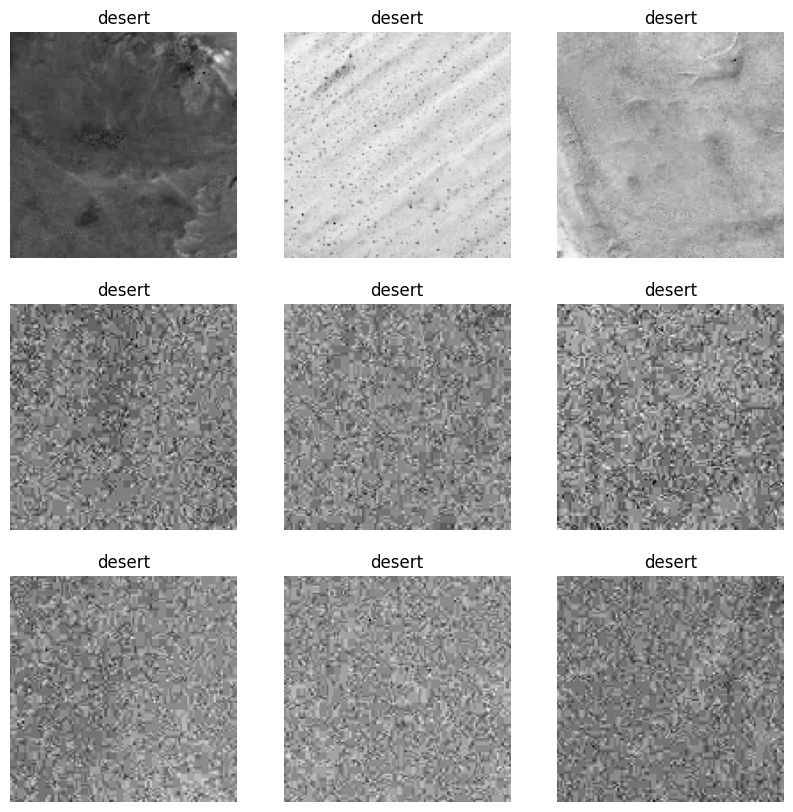

In [28]:
import mahotas as mh

def preprocess_images(images):
    preprocessed_images = []
    for img in images:
        # Проверка и конвертация типа изображения
        if img.dtype == np.float64:
            img = (img * 255).astype(np.uint8)  # или img = img.astype(np.float32)
        # изменение размера
        img_resized = cv2.resize(img, (128, 128))
        # преобразование в оттенки серого (если изображение еще не в градациях серого)
        if len(img_resized.shape) == 3:  # если цветное изображение
            img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
        else:
            img_gray = img_resized
        # уменьшение контраста
        contrast_img = mh.stretch(img_gray**0.6)
        # нормализация
        normalized_img = contrast_img.astype(np.float32) / 255.0
        preprocessed_images.append(normalized_img)
    return np.array(preprocessed_images)


preprocessed_images = preprocess_images(images)

# выведем несколько изображений
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(preprocessed_images[i], cmap="gray")
    ax.set_title(labels[i])
    ax.axis("off")
plt.show()

Разбиваем на выборки

In [29]:
from sklearn.model_selection import train_test_split

# X_train, X_test, y_train, y_test = train_test_split(preprocessed_images, labels_encoded,test_size=0.2, random_state=42, stratify=labels_encoded)
X_train, X_test, y_train, y_test = train_test_split(
    preprocessed_images, labels, test_size=0.2, random_state=42, stratify=labels
)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (1809, 128, 128)
Размер тестовой выборки: (453, 128, 128)


In [30]:
import keras
from keras.api.models import Sequential
from keras.api.layers import Dense, InputLayer, BatchNormalization, Dropout

# преобразование входов в 1-мерные вектора, чтобы нейросеть могла их обработать
# каждое фото (вход) - матрица (2-мерный вектор) 128 на 128
# после преобразования 1 фото - 1-мерный вектор размером 128*128=16384
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)


from sklearn.preprocessing import LabelEncoder

# Унитарное кодирование
le = LabelEncoder()
# desert -> 0, water -> 1
y_train_encoded = le.fit_transform(y_train)
# water -> 0, desert -> 1
y_train_encoded = 1 - y_train_encoded
y_test_encoded = le.transform(y_test)
y_test_encoded = 1 - y_test_encoded

y_train = keras.utils.to_categorical(y_train_encoded, num_classes=2)
y_test = keras.utils.to_categorical(y_test_encoded, num_classes=2)


model = Sequential()
# входной слой с кол-вом нейронов 128*128=16384
model.add(InputLayer(shape=(X_train.shape[1],)))
# полносвязный скрытый слой с 512 нейронами и ф-ей активации Relu
model.add(Dense(512, activation="relu"))
# вспомогательный скрытый слой
# нормализует выходы предыдущего слоя, ускоряет обучение
model.add(BatchNormalization())
# вспомогательный скрытый слой
# случайно "отключает" 30% нейронов Dense-слоя, предотвращает переобучение
model.add(Dropout(0.3))
# ПО АНАЛОГИИ 2 СКРЫТЫХ ПОЛНОСВЯЗНЫХ СЛОЯ + ПО 2 ВСПОМОГАТЕЛЬНЫХ
model.add(Dense(256, activation="relu"))

model.add(BatchNormalization())

model.add(Dropout(0.3))

model.add(Dense(128, activation="relu"))

model.add(BatchNormalization())

model.add(Dropout(0.2))

# выходной слой с 2 нейронами (2 класса)
model.add(Dense(2, activation="softmax"))


model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_29 (Dense)                │ (None, 512)            │     8,389,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,557,186 (32.64 MB)

 Trainable params: 8,555,394 (32.64 MB)

 Non-trainable params: 1,792 (7.00 KB)

Обучение

In [31]:
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)
history = model.fit(
    X_train, y_train, batch_size=64, epochs=50, validation_data=(X_test, y_test)
)

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.6422 - loss: 0.8633 - val_accuracy: 0.5475 - val_loss: 5.9951
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.7496 - loss: 0.5402 - val_accuracy: 0.6071 - val_loss: 1.3918
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7613 - loss: 0.5160 - val_accuracy: 0.6755 - val_loss: 0.7648
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7750 - loss: 0.5008 - val_accuracy: 0.6667 - val_loss: 0.6060
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.8222 - loss: 0.4308 - val_accuracy: 0.7594 - val_loss: 0.4949
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8282 - loss: 0.4151 - val_accuracy: 0.7660 - val_loss: 0.4573
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.8290 - loss: 0.3865 - val_accuracy: 0.5011 - val_loss: 0.9820
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8402 - loss: 0.3651 - val_accuracy: 0.5232 - v

Точность у модели во время обучения достаточно высокая (начало - 0.66, в конце - 0.9), но невелика у тестовой выборки (долгое время начало - 0.49, в конце - 0.56).

Попробуем сократить количество слоев до 2 и установим dropout после dense(256) равное 0,2.

In [32]:
model1 = Sequential()
# входной слой с кол-вом нейронов 128*128=16384
model1.add(InputLayer(shape=(X_train.shape[1],)))
# полносвязный скрытый слой с 512 нейронами и ф-ей активации Relu
model1.add(Dense(512, activation="relu"))
# вспомогательный скрытый слой
# нормализует выходы предыдущего слоя, ускоряет обучение
model1.add(BatchNormalization())
# вспомогательный скрытый слой
# случайно "отключает" 30% нейронов Dense-слоя, предотвращает переобучение
model1.add(Dropout(0.3))
# ПО АНАЛОГИИ 2 СКРЫТЫХ ПОЛНОСВЯЗНЫХ СЛОЯ + ПО 2 ВСПОМОГАТЕЛЬНЫХ
model1.add(Dense(256, activation="relu"))

model1.add(BatchNormalization())

model1.add(Dropout(0.2))

# выходной слой с 2 нейронами (2 класса)
model1.add(Dense(2, activation="softmax"))


model1.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_33 (Dense)                │ (None, 512)            │     8,389,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,524,034 (32.52 MB)

 Trainable params: 8,522,498 (32.51 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [33]:
model1.compile(
    loss="binary_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"],
)
history2 = model1.fit(
    X_train, y_train, batch_size=64, epochs=50, validation_data=(X_test, y_test)
)

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.6428 - loss: 0.8044 - val_accuracy: 0.5475 - val_loss: 1.0322
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7652 - loss: 0.5203 - val_accuracy: 0.5740 - val_loss: 0.9661
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8065 - loss: 0.4602 - val_accuracy: 0.6291 - val_loss: 0.6546
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8064 - loss: 0.4472 - val_accuracy: 0.4967 - val_loss: 0.9456
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8134 - loss: 0.4200 - val_accuracy: 0.4570 - val_loss: 0.9580
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8468 - loss: 0.3784 - val_accuracy: 0.4812 - val_loss: 1.2966
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8217 - loss: 0.3964 - val_accuracy: 0.4989 - val_loss: 1.3913
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8271 - loss: 0.4067 - val_accuracy: 0.4592 - v

In [34]:
model2 = Sequential()
# входной слой с кол-вом нейронов 128*128=16384
model2.add(InputLayer(shape=(X_train.shape[1],)))
# полносвязный скрытый слой с 512 нейронами и ф-ей активации Relu
model2.add(Dense(512, activation="relu"))
# вспомогательный скрытый слой
# нормализует выходы предыдущего слоя, ускоряет обучение
model2.add(BatchNormalization())
# вспомогательный скрытый слой
# случайно "отключает" 30% нейронов Dense-слоя, предотвращает переобучение
model2.add(Dropout(0.3))
# ПО АНАЛОГИИ 2 СКРЫТЫХ ПОЛНОСВЯЗНЫХ СЛОЯ + ПО 2 ВСПОМОГАТЕЛЬНЫХ
model2.add(Dense(256, activation="relu"))

model2.add(BatchNormalization())

model2.add(Dropout(0.2))

# выходной слой с 2 нейронами (2 класса)
model2.add(Dense(2, activation="softmax"))


model2.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 512)            │     8,389,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,524,034 (32.52 MB)

 Trainable params: 8,522,498 (32.51 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [35]:
model2.compile(
    loss="binary_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"],
)
# раннее прерывание обучения, если нет улучшений на протяжении 10 эпох (если разница в точности менее 0.01)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    min_delta=0.001,
    patience=10,
    restore_best_weights=True,
)

history4 = model2.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=50,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping],
)

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.6689 - loss: 0.7302 - val_accuracy: 0.6380 - val_loss: 0.6508
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7664 - loss: 0.5644 - val_accuracy: 0.5982 - val_loss: 0.7811
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8137 - loss: 0.4724 - val_accuracy: 0.7439 - val_loss: 0.5627
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8321 - loss: 0.4231 - val_accuracy: 0.4349 - val_loss: 1.5142
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8246 - loss: 0.4068 - val_accuracy: 0.6269 - val_loss: 0.6201
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8387 - loss: 0.3755 - val_accuracy: 0.4150 - val_loss: 1.3256
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8369 - loss: 0.4078 - val_accuracy: 0.4614 - val_loss: 0.7445
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8406 - loss: 0.3820 - val_accuracy: 0.4989 - v

Вывод: лучшее качество имеет первая модель, которая показала результат до 76,6% способности к обобщению.